# 02 - Phân tích dữ liệu khám phá (EDA)

**Input:** `data/processed/redd_plus_cleaned.csv` (output của `01_data_cleaning.ipynb`)

**Mục tiêu:** hiểu phân bố biến mục tiêu `priority`, tìm các yếu tố liên quan đến mức độ ưu tiên, kiểm tra các biến
có nguy cơ gây nhiễu (`year`, `status`), và có cái nhìn đầu tiên về phân bố không gian — làm cơ sở cho bước chọn đặc trưng
ở notebook 03 và phân tích không gian ở notebook 04.

## 1. Thiết lập & đọc dữ liệu

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "outputs" / "figures"
TABLE_DIR = ROOT / "outputs" / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})

# Thứ tự & màu thống nhất cho toàn bộ đồ án (dùng lại trong ArcGIS/Power BI)
PRIORITY_ORDER = ["High", "Medium", "Low"]
PRIORITY_COLORS = {"High": "#d7191c", "Medium": "#fdae61", "Low": "#1a9641"}
COLORS = [PRIORITY_COLORS[p] for p in PRIORITY_ORDER]

df = pd.read_csv(ROOT / "data" / "processed" / "redd_plus_cleaned.csv", parse_dates=["date"])
df["priority"] = pd.Categorical(df["priority"], categories=PRIORITY_ORDER, ordered=True)
print(f"{len(df):,} dòng × {df.shape[1]} cột")
df.head(3)

18,851 dòng × 27 cột


,id,latitude,longitude,province,district,commune,sub_region,spatial_group,plot,lot,site,forest_owner,owner_type,land_type,forest_origin,land_cover_group,stock_level,stock_ord,date,year,month,status,priority,dist_to_district_center_km,coord_decimals,low_precision_coord,n_same_coord
0,1,11.5169,108.272668,Lam Dong,Di Linh,Tam Bo,678,LamDong_678,3.0,26.0,Tam Bo,Trần Ngọc Thế,Household/individual,Medium coniferous natural forest,Natural forest,Coniferous,Medium,3,2018-01-01,2018,1,Verified,High,25.77,4,False,1
1,2,11.4464,108.062816,Lam Dong,Di Linh,Gung Re,695,LamDong_695,5.0,1.0,Gung Re village,Forestry One Member Limited Liability Company ...,Company,Medium coniferous natural forest,Natural forest,Coniferous,Medium,3,2018-01-01,2018,1,Verified,High,2.67,4,False,1
2,3,11.4462,108.062886,Lam Dong,Di Linh,Gung Re,695,LamDong_695,5.0,3.0,Gung Re village,Forestry One Member Limited Liability Company ...,Company,Natural wood forest in the mountains with medi...,Natural forest,Broadleaf-coniferous mixed,Medium,3,2018-01-01,2018,1,Verified,High,2.65,4,False,1


In [2]:
def pct_crosstab(index, columns=None, normalize="index"):
    """Crosstab tỷ lệ % theo dòng, cột Priority luôn theo thứ tự High-Medium-Low."""
    columns = df["priority"] if columns is None else columns
    return (pd.crosstab(index, columns, normalize=normalize) * 100).round(1)


def stacked_pct_bar(index, title, fname, ax=None, sort_by_high=True):
    tab = pct_crosstab(index)
    if sort_by_high:
        tab = tab.sort_values("High")
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.45 * len(tab) + 1.5))
    tab.plot(kind="barh", stacked=True, color=COLORS, ax=ax, width=0.8, edgecolor="white")
    counts = index.value_counts()
    ax.set_yticklabels([f"{i} (n={counts[i]:,})" for i in tab.index])
    ax.set_xlabel("% số điểm"); ax.set_ylabel(""); ax.set_title(title)
    ax.legend(title="Priority", bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.set_xlim(0, 100)
    if show:
        plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches="tight"); plt.show()
    return tab

## 2. Thống kê mô tả tổng quan

In [3]:
df.describe(include="all").T[["count", "unique", "top", "freq", "mean", "min", "max"]]

,count,unique,top,freq,mean,min,max
id,18851.0,NaN,NaN,NaN,18914.394462,1.0,40392.0
latitude,18851.0,NaN,NaN,NaN,17.199251,11.2387,19.40872
longitude,18851.0,NaN,NaN,NaN,105.504119,104.006694,108.716802
province,18851,2,Nghe An,13461,NaN,NaN,NaN
district,18851,4,Ky Son,8733,NaN,NaN,NaN
commune,18851,35,Na Ngoi,4513,NaN,NaN,NaN
sub_region,18851,279,461,590,NaN,NaN,NaN
spatial_group,18851,303,NgheAn_461,590,NaN,NaN,NaN
plot,18611.0,NaN,NaN,NaN,5.879641,1.0,24.0
lot,17790.0,NaN,NaN,NaN,18.016189,1.0,253.0


## 3. Biến mục tiêu `priority`

### 3.1 Phân bố chung và theo tỉnh

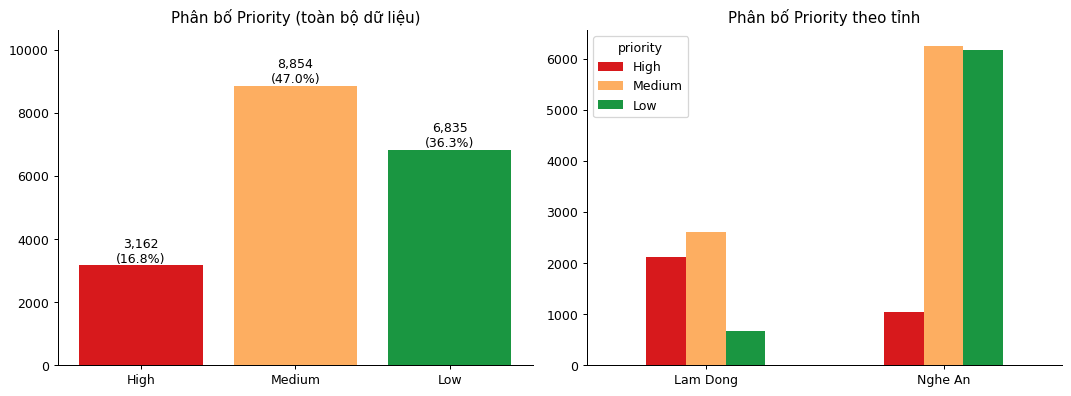

Số điểm              % theo tỉnh             
priority    High Medium   Low        High Medium   Low
province                                              
Lam Dong    2120   2604   666        39.3   48.3  12.4
Nghe An     1042   6250  6169         7.7   46.4  45.8

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

vc = df["priority"].value_counts().reindex(PRIORITY_ORDER)
axes[0].bar(vc.index, vc.values, color=COLORS)
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("Phân bố Priority (toàn bộ dữ liệu)"); axes[0].set_ylim(0, vc.max() * 1.2)

ct = pd.crosstab(df["province"], df["priority"])
ct.plot(kind="bar", color=COLORS, ax=axes[1], rot=0)
axes[1].set_title("Phân bố Priority theo tỉnh"); axes[1].set_xlabel("")

plt.tight_layout(); plt.savefig(FIG_DIR / "eda_priority_distribution.png", bbox_inches="tight"); plt.show()

display(pd.concat({"Số điểm": ct, "% theo tỉnh": pct_crosstab(df["province"])}, axis=1))

Lớp **High chỉ chiếm ~16%** → mất cân bằng vừa phải. Khi đánh giá phải dùng **F1-macro / balanced accuracy** thay vì chỉ
Accuracy, và dùng `class_weight="balanced"` khi huấn luyện.

### 3.2 Phát hiện quan trọng: Priority gần như được quyết định bởi nguồn gốc rừng

In [5]:
tab = pd.crosstab(df["forest_origin"], df["priority"], margins=True)
display(tab)
display(pct_crosstab(df["forest_origin"]))

# "Mô hình luật" đơn giản: rừng tự nhiên -> Medium, rừng trồng -> Low
rule_pred = np.where(df["forest_origin"] == "Natural forest", "Medium", "Low")
print(f"Accuracy của luật 1 dòng (tự nhiên→Medium, trồng→Low): {(rule_pred == df['priority']).mean():.3f}")

priority,High,Medium,Low,All
forest_origin,,,,
Natural forest,3143,7866,105,11114
Plantation forest,19,988,6730,7737
All,3162,8854,6835,18851


priority,High,Medium,Low
forest_origin,,,
Natural forest,28.3,70.8,0.9
Plantation forest,0.2,12.8,87.0


**Insight #1 (rất quan trọng cho báo cáo):**
- ~99% điểm **Low là rừng trồng/đất chưa có rừng**, và rừng tự nhiên gần như không bao giờ bị xếp Low.
- Chỉ với 1 luật đơn giản đã đạt Accuracy ~0,77 → đây là **baseline tối thiểu** mà mọi mô hình học máy phải vượt qua.
- **Phần khó thật sự của bài toán là phân biệt High và Medium trong rừng tự nhiên.** Notebook 03 sẽ đánh giá riêng phần này.

### 3.3 Priority theo nhóm hiện trạng rừng và cấp trữ lượng

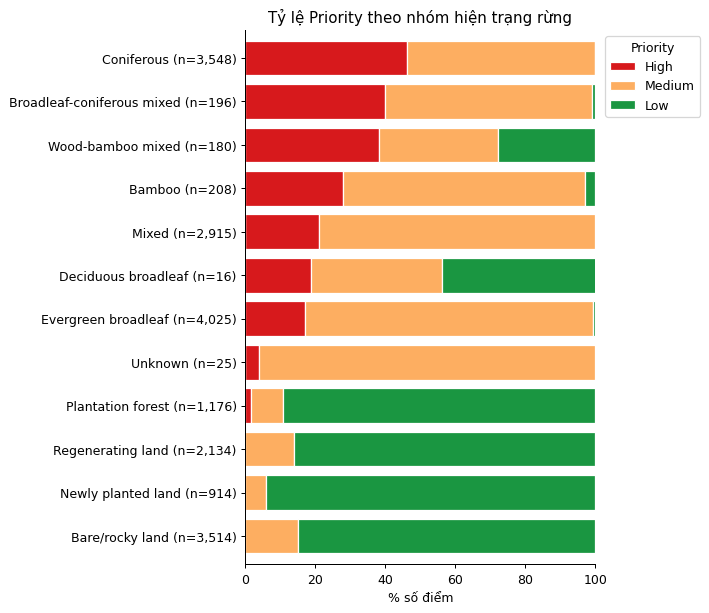

priority,High,Medium,Low
land_cover_group,,,
Bare/rocky land,0.0,15.0,85.0
Newly planted land,0.0,6.0,94.0
Regenerating land,0.0,14.0,86.0
Plantation forest,1.6,9.1,89.3
Unknown,4.0,96.0,0.0
Evergreen broadleaf,17.1,82.1,0.8
Deciduous broadleaf,18.8,37.5,43.8
Mixed,20.9,79.1,0.0
Bamboo,27.9,69.2,2.9


In [6]:
stacked_pct_bar(df["land_cover_group"], "Tỷ lệ Priority theo nhóm hiện trạng rừng", "eda_priority_by_land_cover.png")

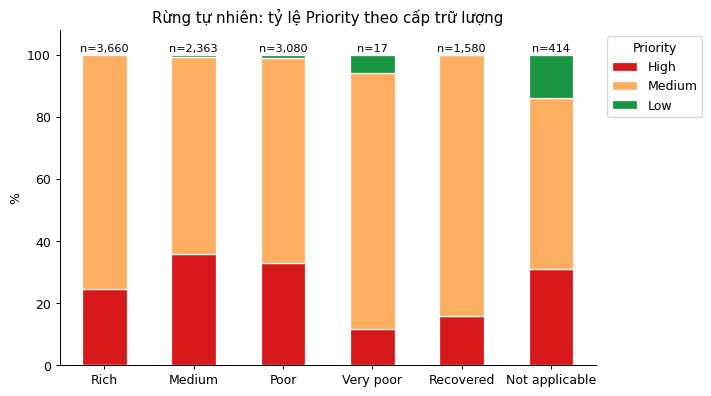

priority,High,Medium,Low
stock_level,,,
Rich,24.5,75.5,0.0
Medium,35.8,63.6,0.6
Poor,33.1,65.9,1.0
Very poor,11.8,82.4,5.9
Recovered,16.0,83.9,0.1
Not applicable,30.9,55.3,13.8


In [7]:
nat = df[df["forest_origin"] == "Natural forest"]
stock_order = ["Rich", "Medium", "Poor", "Very poor", "Recovered", "Not applicable"]
tab = pct_crosstab(nat["stock_level"]).reindex([s for s in stock_order if s in nat["stock_level"].unique()])

ax = tab.plot(kind="bar", stacked=True, color=COLORS, figsize=(8, 4.5), rot=0, edgecolor="white")
for i, (s, n) in enumerate(nat["stock_level"].value_counts().reindex(tab.index).items()):
    ax.text(i, 101, f"n={n:,}", ha="center", fontsize=9)
ax.set_title("Rừng tự nhiên: tỷ lệ Priority theo cấp trữ lượng"); ax.set_ylabel("%"); ax.set_xlabel("")
ax.legend(title="Priority", bbox_to_anchor=(1.01, 1), loc="upper left"); ax.set_ylim(0, 108)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_natural_priority_by_stock.png", bbox_inches="tight"); plt.show()
tab

### 3.4 Priority theo huyện và loại chủ rừng

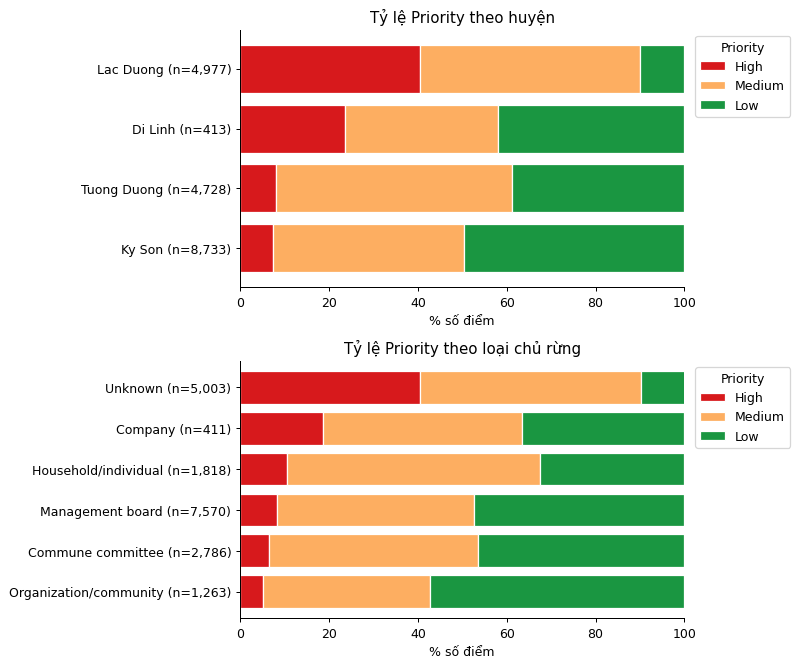

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7.5))
stacked_pct_bar(df["district"], "Tỷ lệ Priority theo huyện", None, ax=axes[0])
stacked_pct_bar(df["owner_type"], "Tỷ lệ Priority theo loại chủ rừng", None, ax=axes[1])
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_priority_by_district_owner.png", bbox_inches="tight"); plt.show()

In [9]:
# Chỉ xét rừng tự nhiên: vẫn còn khác biệt giữa 2 tỉnh?
display(pct_crosstab(nat["province"]))
display(pct_crosstab(nat["district"]))

priority,High,Medium,Low
province,,,
Lam Dong,44.6,53.2,2.2
Nghe An,16.3,83.7,0.0


priority,High,Medium,Low
district,,,
Di Linh,27.7,35.1,37.2
Ky Son,18.4,81.6,0.0
Lac Duong,45.7,54.3,0.0
Tuong Duong,13.6,86.4,0.0


**Insight #2:** Ngay cả khi chỉ xét rừng tự nhiên, tỷ lệ High ở Lâm Đồng (~45%) vẫn cao gấp ~3 lần Nghệ An (~16%).
Như vậy ngoài loại rừng còn có **yếu tố vùng/địa phương** (chính sách, cách phân cấp của từng huyện) → đây là lý do đưa
`province`/`district` vào mô hình. Việc có cần thêm toạ độ chi tiết (lat/long, cụm không gian) hay không sẽ được kiểm chứng
bằng thí nghiệm ablation ở notebook 03, và cấu trúc không gian được kiểm định bằng Moran's I ở notebook 04.

## 4. Mức độ liên hệ giữa từng biến và Priority (Cramér's V)

Cramér's V ∈ [0, 1] đo độ mạnh liên hệ giữa 2 biến phân loại (0 = không liên hệ, 1 = quyết định hoàn toàn).
Tính trên toàn bộ dữ liệu và riêng rừng tự nhiên (bài toán High vs Medium).

In [10]:
def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    if min(tab.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    r, k = tab.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


cand = ["forest_origin", "land_cover_group", "stock_level", "land_type", "province", "district",
        "commune", "owner_type", "status", "year", "month"]
nat_y = nat["priority"].astype(str)
assoc = pd.DataFrame({
    "Cramér's V (toàn bộ)": [cramers_v(df[c], df["priority"]) for c in cand],
    "Cramér's V (rừng tự nhiên)": [cramers_v(nat[c], nat_y) for c in cand],
    "Số giá trị": [df[c].nunique() for c in cand],
}, index=cand).round(3).sort_values("Cramér's V (toàn bộ)", ascending=False)
assoc.to_csv(TABLE_DIR / "eda_cramers_v.csv", encoding="utf-8-sig")
assoc

,Cramér's V (toàn bộ),Cramér's V (rừng tự nhiên),Số giá trị
forest_origin,0.884,NaN,2
land_type,0.676,0.488,50
land_cover_group,0.659,0.354,12
stock_level,0.614,0.217,6
province,0.430,0.338,2
commune,0.356,0.529,35
year,0.352,0.287,8
owner_type,0.320,0.396,6
district,0.319,0.485,4
month,0.138,0.135,12


**Đọc bảng:**
- Với toàn bộ dữ liệu, `forest_origin` / `land_cover_group` liên hệ mạnh nhất (vì quyết định lớp Low).
- Trong rừng tự nhiên, các biến về **vị trí** (`district`, `commune`, `province`) và `land_type` chi tiết liên hệ mạnh hơn → vị trí địa lý
  đóng vai trò lớn trong việc phân biệt High/Medium.
- `status` gần như không liên hệ với Priority, lại là thông tin có **sau** khi xử lý điểm → **loại khỏi mô hình**.
- `year` có liên hệ nhưng chủ yếu do trùng với tỉnh (xem mục 5) → **loại khỏi mô hình**.
- `commune` (35 giá trị) chủ yếu lặp lại thông tin vị trí và dễ overfit khi đánh giá theo tiểu khu → không dùng trực tiếp;
  thông tin vị trí được đưa vào qua `province`, `district` và toạ độ.
- `land_type` (50 giá trị) liên hệ mạnh nhất trong rừng tự nhiên → giữ lại cùng với các nhóm đã gom (`land_cover_group`, `stock_level`).

## 5. Yếu tố thời gian — vì sao không dùng `year` làm đặc trưng

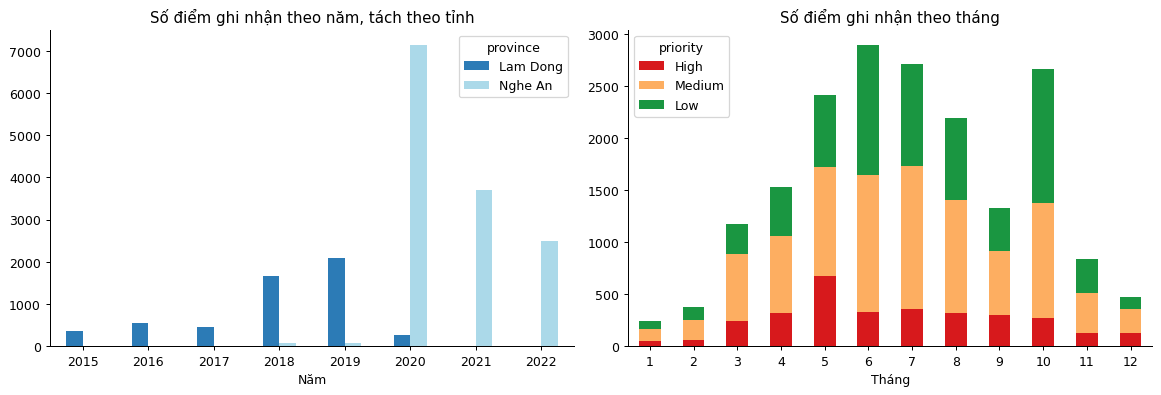

province,Lam Dong,Nghe An
year,,
2015,357,0
2016,555,0
2017,454,0
2018,1654,69
2019,2093,68
2020,277,7141
2021,0,3698
2022,0,2485


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pd.crosstab(df["year"], df["province"]).plot(kind="bar", ax=axes[0], rot=0, color=["#2c7bb6", "#abd9e9"])
axes[0].set_title("Số điểm ghi nhận theo năm, tách theo tỉnh"); axes[0].set_xlabel("Năm")

m = pd.crosstab(df["month"], df["priority"])
m.plot(kind="bar", stacked=True, color=COLORS, ax=axes[1], rot=0)
axes[1].set_title("Số điểm ghi nhận theo tháng"); axes[1].set_xlabel("Tháng")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_time.png", bbox_inches="tight"); plt.show()

pd.crosstab(df["year"], df["province"])

Lâm Đồng có dữ liệu 2015–2020, Nghệ An tập trung 2020–2022 → `year` chủ yếu phản ánh **tỉnh nào đang được khảo sát**,
không phải đặc điểm của lô rừng. Đưa vào mô hình sẽ gây hiểu nhầm về tầm quan trọng của "thời gian".

## 6. Biến `status` — vì sao không chọn làm biến mục tiêu

In [12]:
display(df["status"].value_counts().to_frame("so_diem").assign(ty_le=lambda t: (t["so_diem"] / len(df) * 100).round(2)))
pct_crosstab(df["status"])

,so_diem,ty_le
status,,
Not Verified,18615,98.75
Verified,236,1.25


priority,High,Medium,Low
status,,,
Not Verified,16.7,46.9,36.4
Verified,24.2,50.8,25.0


Chỉ ~1,2% điểm `Verified` → nếu làm target sẽ mất cân bằng cực đoan (1:80). Tỷ lệ Priority trong 2 nhóm Status cũng tương tự
nhau → Status không mang thông tin về Priority.

## 7. Phân bố không gian ban đầu

Hai tỉnh cách nhau ~800 km → vẽ **riêng từng tỉnh**. (Bản đồ có nền và ranh giới sẽ làm trên ArcGIS từ file xuất ở notebook 04.)

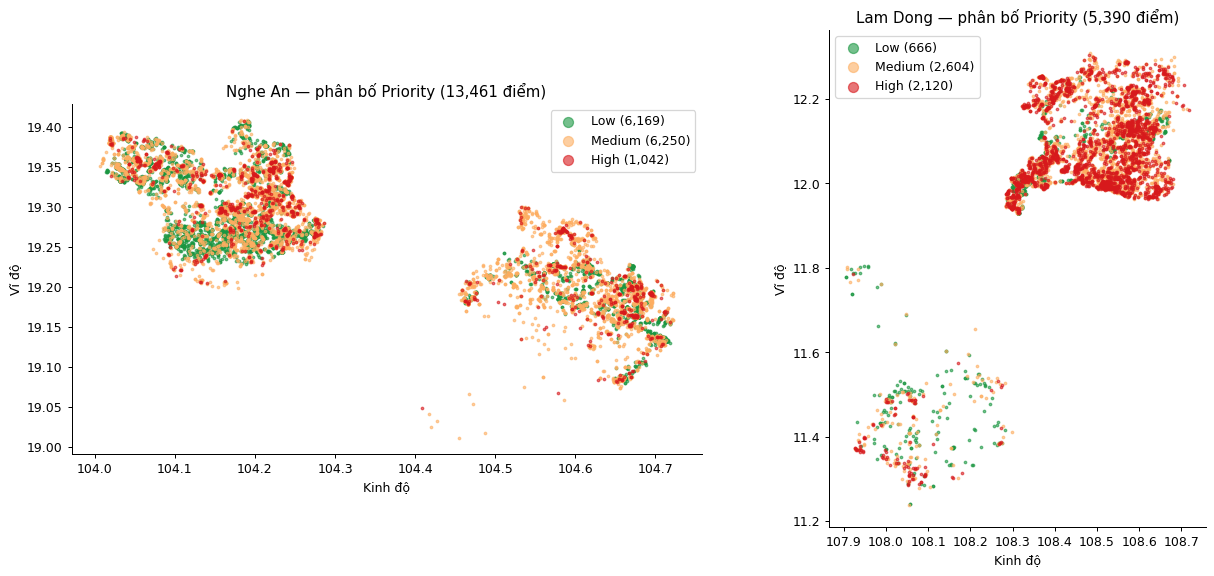

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, prov in zip(axes, ["Nghe An", "Lam Dong"]):
    sub = df[df["province"] == prov]
    for p in ["Low", "Medium", "High"]:          # vẽ High sau cùng để nổi lên trên
        s = sub[sub["priority"] == p]
        ax.scatter(s["longitude"], s["latitude"], s=4, c=PRIORITY_COLORS[p], label=f"{p} ({len(s):,})", alpha=0.6)
    ax.set_title(f"{prov} — phân bố Priority ({len(sub):,} điểm)")
    ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ"); ax.set_aspect("equal")
    ax.legend(markerscale=4, loc="best")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_map_priority.png", bbox_inches="tight"); plt.show()

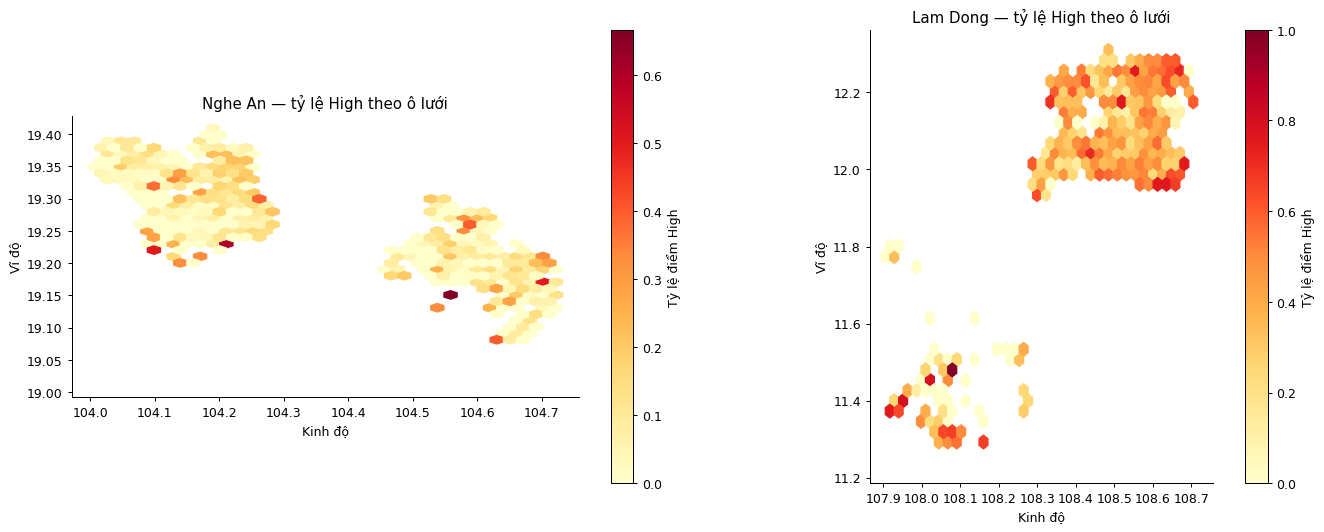

In [14]:
# Tỷ lệ High theo ô lưới lục giác (hexbin): cho thấy các "vùng nóng" ưu tiên cao
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, prov in zip(axes, ["Nghe An", "Lam Dong"]):
    sub = df[df["province"] == prov]
    hb = ax.hexbin(sub["longitude"], sub["latitude"], C=(sub["priority"] == "High").astype(float),
                   reduce_C_function=np.mean, gridsize=35, cmap="YlOrRd", mincnt=3)
    plt.colorbar(hb, ax=ax, label="Tỷ lệ điểm High")
    ax.set_title(f"{prov} — tỷ lệ High theo ô lưới"); ax.set_aspect("equal")
    ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_map_high_share_hexbin.png", bbox_inches="tight"); plt.show()

Điểm High tập trung thành **cụm** chứ không rải ngẫu nhiên → gợi ý có **tự tương quan không gian**. Notebook 04 sẽ kiểm định
bằng Moran's I và tìm vùng nóng bằng Getis-Ord Gi*.

## 8. Mức độ nhiễu nhãn & "trần" độ chính xác

Nếu nhiều điểm có **cùng toàn bộ đặc trưng** nhưng nhãn khác nhau thì không mô hình nào phân biệt được chúng.
Với mỗi tổ hợp đặc trưng, mô hình tốt nhất có thể làm là đoán nhãn phổ biến nhất của tổ hợp đó → tỷ lệ đúng tối đa
(*trên tập huấn luyện*) gọi là **trần độ chính xác** của tập đặc trưng. Đây là con số tham chiếu quan trọng khi đọc kết quả notebook 03.

In [15]:
def accuracy_ceiling(keys):
    """Tỷ lệ đúng tối đa nếu với mỗi tổ hợp `keys` luôn đoán nhãn phổ biến nhất."""
    g = df.groupby(keys, observed=True)["priority"]
    return g.agg(lambda s: s.value_counts().iloc[0]).sum() / len(df), g.ngroups


ceiling_sets = {
    "Nguồn gốc rừng": ["forest_origin"],
    "Loại đất chi tiết (land_type)": ["land_type"],
    "land_type + huyện": ["land_type", "district"],
    "land_type + huyện + loại chủ rừng": ["land_type", "district", "owner_type"],
    "land_type + tiểu khu + loại chủ rừng": ["land_type", "spatial_group", "owner_type"],
    "Toạ độ chính xác (lat, long)": ["latitude", "longitude"],
}
ceil = pd.DataFrame([(k, *accuracy_ceiling(v)) for k, v in ceiling_sets.items()],
                    columns=["Tập đặc trưng", "Trần accuracy (trên train)", "Số tổ hợp"]).round(4)
ceil.to_csv(TABLE_DIR / "eda_accuracy_ceiling.csv", index=False, encoding="utf-8-sig")
ceil

,Tập đặc trưng,Trần accuracy (trên train),Số tổ hợp
0,Nguồn gốc rừng,0.7743,2
1,Loại đất chi tiết (land_type),0.7809,50
2,land_type + huyện,0.7829,75
3,land_type + huyện + loại chủ rừng,0.7841,142
4,land_type + tiểu khu + loại chủ rừng,0.8106,1364
5,"Toạ độ chính xác (lat, long)",0.9827,17767


**Đọc bảng:**
- Chỉ với `land_type`, trần accuracy đã ~0,78; thêm huyện, loại chủ rừng gần như **không tăng**. Ngay cả khi biết tới từng tiểu khu
  (1.364 tổ hợp — gần như học thuộc) cũng chỉ ~0,81.
- Nghĩa là khoảng **20% nhãn không thể giải thích bằng các thuộc tính có trong dữ liệu** (nhiễu nhãn, hoặc nhãn phụ thuộc yếu tố
  không được ghi lại như độ dốc, khoảng cách tới khu dân cư, nguy cơ cháy...).
- Trần theo toạ độ chính xác rất cao chỉ vì hầu hết toạ độ là duy nhất (mỗi tổ hợp 1 điểm) → đó là **học thuộc**, không có ý nghĩa dự báo.
- → Mô hình ở notebook 03 đạt accuracy ~0,75–0,78 là **sát trần**; muốn cải thiện đáng kể cần **bổ sung dữ liệu mới**
  (DEM/độ dốc, khoảng cách đường/sông/dân cư, ảnh vệ tinh...), không phải đổi thuật toán.

## 9. Bảng tổng hợp theo huyện (đưa vào báo cáo / Power BI)

In [16]:
summary = df.groupby(["province", "district"]).agg(
    so_diem=("id", "size"),
    ty_le_rung_tu_nhien=("forest_origin", lambda x: (x == "Natural forest").mean()),
    ty_le_high=("priority", lambda x: (x == "High").mean()),
    ty_le_medium=("priority", lambda x: (x == "Medium").mean()),
    ty_le_low=("priority", lambda x: (x == "Low").mean()),
    so_tieu_khu=("spatial_group", "nunique"),
).round(3)
summary.to_csv(TABLE_DIR / "eda_summary_by_district.csv", encoding="utf-8-sig")
summary

so_diem  ty_le_rung_tu_nhien  ...  ty_le_low  so_tieu_khu
province district                                   ...                        
Lam Dong Di Linh          413                0.683  ...      0.419           88
         Lac Duong       4977                0.889  ...      0.099          117
Nghe An  Ky Son          8733                0.411  ...      0.496           47
         Tuong Duong     4728                0.595  ...      0.389           51

[4 rows x 6 columns]

## Kết luận bước 2 — Insight chính

1. **Low ≈ rừng trồng / đất chưa có rừng**: một luật 1 dòng đã đạt Accuracy ~0,77 → đây là baseline bắt buộc phải so sánh.
2. **Bài toán khó là High vs Medium trong rừng tự nhiên**; ở đây cấp trữ lượng, loại rừng và đặc biệt là **vị trí (huyện/xã/toạ độ)** có vai trò quan trọng.
3. Lâm Đồng có tỷ lệ High cao hơn Nghệ An kể cả khi chỉ xét rừng tự nhiên → có yếu tố địa phương/không gian.
4. `status` và `year` **không** đưa vào mô hình (lý do: status là thông tin sau xử lý và không liên quan; year trùng với tỉnh).
5. Điểm High phân bố theo cụm → cần đánh giá mô hình theo **nhóm không gian** (GroupKFold theo tiểu khu) và kiểm định Moran's I.
6. Dữ liệu có **nhiễu nhãn đáng kể**: trần accuracy của các thuộc tính sẵn có chỉ khoảng 0,78–0,81 → đây là mốc tham chiếu khi
   đánh giá mô hình, và là cơ sở đề xuất bổ sung dữ liệu địa hình/kinh tế–xã hội ở hướng phát triển.